# Phase 2: materials, slab waveguide and phase matching

This notebook only calls the `fepc` package and the figure script. The theory is in `docs/theory.md`, and the checks are in `tests/test_materials.py`, `tests/test_slab.py` and `tests/test_coupling.py`.

In [1]:
import sys

from fepc.constants import ev_to_joule, joule_to_ev
from fepc.coupling import (
    decay_length_at_phase_matching,
    phase_matched_kinetic_energy,
    phase_matched_thickness,
)
from fepc.materials import group_index, silica_index, silicon_index, silicon_nitride_index
from fepc.slab import tm0_cutoff_thickness, tm0_finite_difference, tm0_mode

sys.path.append("../scripts")
import make_figures

%matplotlib inline

WAVELENGTH = 1550e-9  # m

## Materials

Index and group index of each material at 1550 nm:

In [2]:
print("Material     n        n_g")
for name, index in [("Si", silicon_index), ("Si3N4", silicon_nitride_index), ("SiO2", silica_index)]:
    print(f"{name:8s}  {index(WAVELENGTH):.4f}   {group_index(index, WAVELENGTH):.4f}")

Material     n        n_g
Si        3.4777   3.6053
Si3N4     1.9963   2.0396
SiO2      1.4440   1.4626


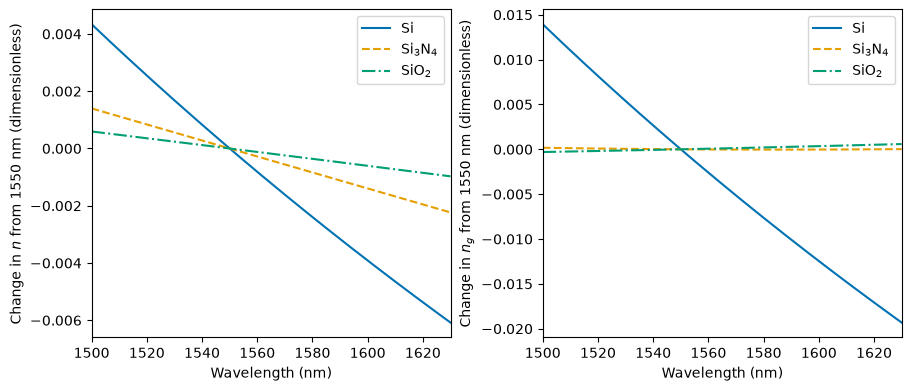

In [3]:
fig = make_figures.materials_dispersion_figure()

## The TM$_0$ mode

These are the checks from the project plan, with the core index held fixed. The last column is the independent finite-difference solver, which never uses the guidance condition.

In [4]:
print("Core   t (nm)  expected  guidance condition  finite differences")
cases = [("Si", 220, 3.476, 1.615), ("Si", 300, 3.476, 2.478), ("Si", 400, 3.476, 2.931),
         ("Si3N4", 800, 1.996, 1.793), ("Si3N4", 400, 1.996, 1.355)]
for name, t_nm, n_core, expected in cases:
    mode = tm0_mode(WAVELENGTH, t_nm * 1e-9, n_core)
    numerical, _, _ = tm0_finite_difference(WAVELENGTH, t_nm * 1e-9, n_core)
    print(f"{name:6s} {t_nm:5d}   {expected:.3f}       {mode.n_eff:.6f}            {numerical:.6f}")

Core   t (nm)  expected  guidance condition  finite differences


Si       220   1.615       1.614908            1.614937
Si       300   2.478       2.478231            2.478242
Si       400   2.931       2.931185            2.931188
Si3N4    800   1.793       1.792500            1.792501
Si3N4    400   1.355       1.354956            1.354959


On a SiO$_2$ substrate TM$_0$ has a cut-off, while a symmetric air-clad film has none. With each material's real index:

In [5]:
n_sub = silica_index(WAVELENGTH)
for name, index in [("Si", silicon_index), ("Si3N4", silicon_nitride_index)]:
    cutoff = tm0_cutoff_thickness(WAVELENGTH, index(WAVELENGTH), n_sub)
    print(f"{name} on SiO2: cut-off at {cutoff * 1e9:.1f} nm")

Si on SiO2: cut-off at 103.3 nm
Si3N4 on SiO2: cut-off at 223.8 nm


The left panel below shows how the mode index climbs from its lowest value towards the core index as the film thickens. The right panel shows that the group index overshoots the bulk value before it settles.

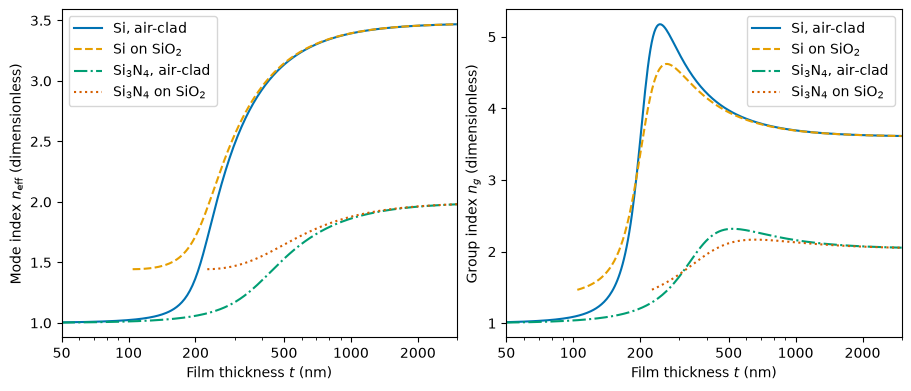

In [6]:
fig = make_figures.slab_index_figure()

The mode reaches out of the film. $H_y$ is largest inside the core, but $E_z$ vanishes at the centre of a symmetric film and is largest just outside its faces, where the electron can reach it.

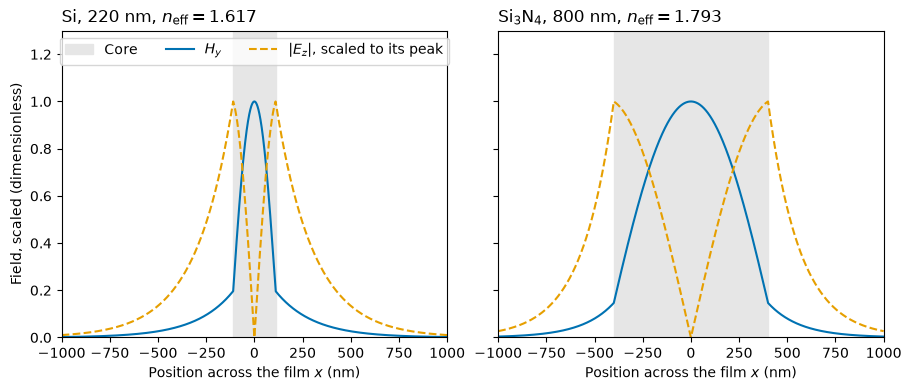

In [7]:
fig = make_figures.slab_mode_figure()

## Phase matching

The electron keeps in step with the wave when $v=c/n_{\rm eff}$. First the checks from the project plan, then the decay length of the field at $n_{\rm eff}=2$:

In [8]:
print("n_eff   E_k (keV)")
for n_eff in [2.000, 2.478, 1.793, 1.615]:
    print(f"{n_eff:.3f}   {joule_to_ev(phase_matched_kinetic_energy(n_eff)) / 1e3:.1f}")

print(f"\nDecay length at n_eff = 2: {decay_length_at_phase_matching(0.5, WAVELENGTH) * 1e9:.1f} nm")

n_eff   E_k (keV)
2.000   79.1
2.478   47.5
1.793   104.6
1.615   139.8

Decay length at n_eff = 2: 142.4 nm


How thick a film must be for each electron energy, with the real indices:

In [9]:
platforms = [("Si, air-clad", silicon_index(WAVELENGTH), 1.0),
             ("Si on SiO2", silicon_index(WAVELENGTH), n_sub),
             ("Si3N4, air-clad", silicon_nitride_index(WAVELENGTH), 1.0),
             ("Si3N4 on SiO2", silicon_nitride_index(WAVELENGTH), n_sub)]
energies_kev = [60, 100, 150, 197, 300]
print("Thickness in nm   " + "".join(f"{e:>9d} keV" for e in energies_kev))
for name, n_core, n_s in platforms:
    cells = []
    for e in energies_kev:
        try:
            t = phase_matched_thickness(ev_to_joule(e * 1e3), WAVELENGTH, n_core, n_s)
            cells.append(f"{t * 1e9:13.1f}")
        except ValueError:
            cells.append(f"{'none':>13s}")
    print(f"{name:17s}" + "".join(cells))

Thickness in nm          60 keV      100 keV      150 keV      197 keV      300 keV
Si, air-clad             271.2        235.2        217.0        206.7        191.3
Si on SiO2               257.0        212.7        177.7        109.9         none
Si3N4, air-clad           none        874.8        533.3        447.9        365.5
Si3N4 on SiO2             none        804.5        423.6        235.5         none


Only air-clad Si covers the whole range. Si$_3$N$_4$ cannot reach below about 79 keV, because its mode index stays below its core index. A SiO$_2$ substrate stops phase matching near 197 keV, because the mode index must stay above the substrate's.

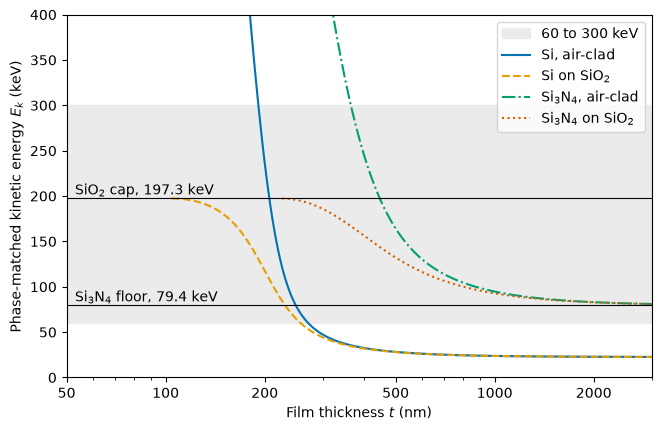

In [10]:
fig = make_figures.phase_matching_figure()